# Segmentation des clients par techniques de clustering

## Contexte

Dans le domaine financier, la segmentation des clients constitue une étape essentielle pour mieux comprendre les profils des utilisateurs et adapter les stratégies commerciales. Les techniques de clustering permettent de regrouper automatiquement des clients présentant des caractéristiques similaires sans disposer d'étiquettes prédéfinies.

## Objectif

L'objectif de ce projet est de segmenter une population de clients à l'aide d'algorithmes d'apprentissage non supervisé afin d'identifier des groupes homogènes présentant des comportements financiers similaires.

## Jeu de données

Le jeu de données contient 2000 clients et plusieurs variables décrivant leur profil financier, notamment :

- âge ;
- revenu annuel ;
- revenu par habitant ;
- dette totale ;
- score de crédit ;
- nombre de cartes bancaires.

Ces informations serviront à construire des segments de clients exploitables pour la prise de décision.

In [69]:
import pandas as pd

In [70]:
#Importation du dataset users_data.csv de Kaggle
users = pd.read_csv(r"C:\Users\rimla\Stage\users_data.csv")
# Afficher les premières lignes du jeu de données?
users.head()
# Afficher les informations générales sur le jeu de données
users.info()
# Afficher les statistiques descriptives des variables numériques
users.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 2000 non-null   int64  
 1   current_age        2000 non-null   int64  
 2   retirement_age     2000 non-null   int64  
 3   birth_year         2000 non-null   int64  
 4   birth_month        2000 non-null   int64  
 5   gender             2000 non-null   object 
 6   address            2000 non-null   object 
 7   latitude           2000 non-null   float64
 8   longitude          2000 non-null   float64
 9   per_capita_income  2000 non-null   object 
 10  yearly_income      2000 non-null   object 
 11  total_debt         2000 non-null   object 
 12  credit_score       2000 non-null   int64  
 13  num_credit_cards   2000 non-null   int64  
dtypes: float64(2), int64(7), object(5)
memory usage: 218.9+ KB


,id,current_age,retirement_age,birth_year,birth_month,latitude,longitude,credit_score,num_credit_cards
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,999.500000,45.391500,66.237500,1973.803000,6.439000,37.389225,-91.554765,709.734500,3.073000
std,577.494589,18.414092,3.628867,18.421234,3.565338,5.114324,16.283293,67.221949,1.637379
min,0.000000,18.000000,50.000000,1918.000000,1.000000,20.880000,-159.410000,480.000000,1.000000
25%,499.750000,30.000000,65.000000,1961.000000,3.000000,33.837500,-97.395000,681.000000,2.000000
50%,999.500000,44.000000,66.000000,1975.000000,7.000000,38.250000,-86.440000,711.500000,3.000000
75%,1499.250000,58.000000,68.000000,1989.000000,10.000000,41.200000,-80.130000,753.000000,4.000000
max,1999.000000,101.000000,79.000000,2002.000000,12.000000,61.200000,-68.670000,850.000000,9.000000


In [71]:
#Afficher la taille du jeu de données
users.shape

(2000, 14)

In [72]:
#Afficher le type des variable
users.dtypes

id                     int64
current_age            int64
retirement_age         int64
birth_year             int64
birth_month            int64
gender                object
address               object
latitude             float64
longitude            float64
per_capita_income     object
yearly_income         object
total_debt            object
credit_score           int64
num_credit_cards       int64
dtype: object

In [73]:
#Vérifier les valeurs manquantes
users.isnull().sum()

id                   0
current_age          0
retirement_age       0
birth_year           0
birth_month          0
gender               0
address              0
latitude             0
longitude            0
per_capita_income    0
yearly_income        0
total_debt           0
credit_score         0
num_credit_cards     0
dtype: int64

## Aucune valeur n'est manquante

In [74]:
#Verifier les doublons
users.duplicated().sum()

np.int64(0)

## Il n'y a pas de doublons

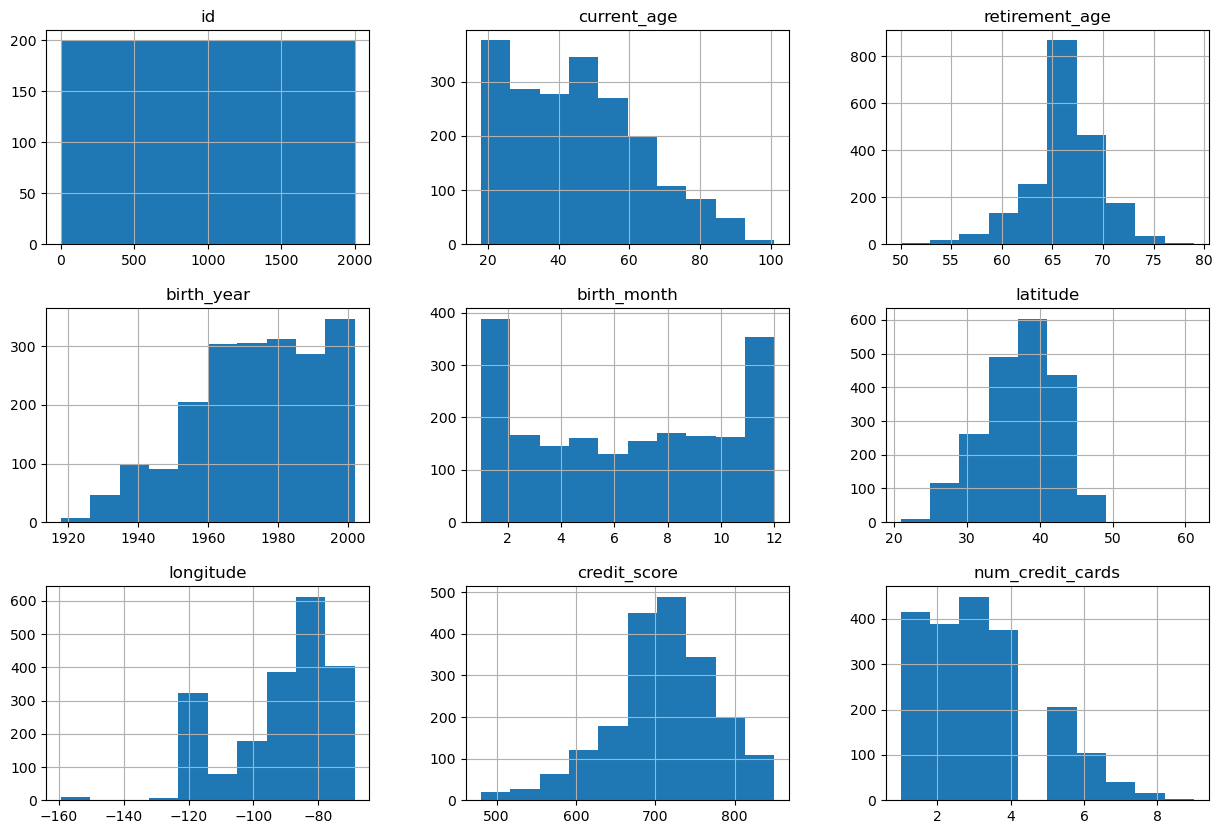

In [75]:
users.hist(figsize=(15,10))
plt.show()


### Les histogrammes permettent d'observer la distribution des principales variables du jeu de données.

- La variable **current_age** présente une répartition relativement étalée, avec une majorité de clients âgés de 20 à 60 ans.
- **retirement_age** est principalement concentrée autour de 65 ans, ce qui correspond à un âge de départ à la retraite classique.
- **birth_year** et **birth_month** reflètent directement la répartition des âges des individus.
- Le **credit_score** suit une distribution proche d'une loi normale, centrée autour de 700, indiquant que la majorité des clients disposent d'un score de crédit moyen à élevé.
- La variable **num_credit_cards** montre que la plupart des clients possèdent entre 1 et 4 cartes de crédit.
- Les variables **latitude** et **longitude** présentent une concentration sur certaines zones géographiques, traduisant la localisation des clients dans des régions spécifiques.
- La variable **id** correspond uniquement à un identifiant unique et n'apporte pas d'information exploitable pour l'analyse.

In [76]:
#Choix des variables pertinentes
X = users[['current_age',
           'per_capita_income',
           'yearly_income',
           'total_debt',
           'credit_score',
           'num_credit_cards']].copy()

## Sélection des variables

Les variables retenues pour le clustering sont les suivantes :

- **current_age** : âge du client ;
- **per_capita_income** : revenu par personne ;
- **yearly_income** : revenu annuel ;
- **total_debt** : dette totale ;
- **credit_score** : score de crédit ;
- **num_credit_cards** : nombre de cartes de crédit.

Ces variables ont été sélectionnées car elles décrivent directement le profil financier et socio-économique des clients. Elles permettent de regrouper des individus présentant des caractéristiques financières similaires, telles que le niveau de revenu, le degré d'endettement, la solvabilité et les habitudes d'utilisation des produits bancaires.

En revanche, les variables d'identification (**id**), géographiques (**latitude**, **longitude**, **address**) et temporelles (**birth_year**, **birth_month**, **retirement_age**) n'ont pas été retenues. Elles n'apportent pas d'information pertinente pour la segmentation financière et risqueraient d'influencer le clustering sans refléter le comportement économique des clients.

In [77]:
#Verification du type des variables choisies
X.dtypes

current_age           int64
per_capita_income    object
yearly_income        object
total_debt           object
credit_score          int64
num_credit_cards      int64
dtype: object

In [78]:
#Transformation des variables de type object en float
X['yearly_income'] = (
    X['yearly_income']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

X['total_debt'] = (
    X['total_debt']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)
X['per_capita_income'] = (
    X['per_capita_income']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [79]:
#Verification du type après transformation
X.dtypes

current_age            int64
per_capita_income    float64
yearly_income        float64
total_debt           float64
credit_score           int64
num_credit_cards       int64
dtype: object

In [80]:
#Vérifier la corrélation entre les variables choisies
X.corr()

,current_age,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
current_age,1.000000,-0.009054,-0.114316,-0.315443,-0.005468,0.484189
per_capita_income,-0.009054,1.000000,0.963975,0.496138,-0.004545,0.018606
yearly_income,-0.114316,0.963975,1.000000,0.550641,0.000167,-0.032877
total_debt,-0.315443,0.496138,0.550641,1.000000,-0.104537,-0.217940
credit_score,-0.005468,-0.004545,0.000167,-0.104537,1.000000,0.237935
num_credit_cards,0.484189,0.018606,-0.032877,-0.217940,0.237935,1.000000


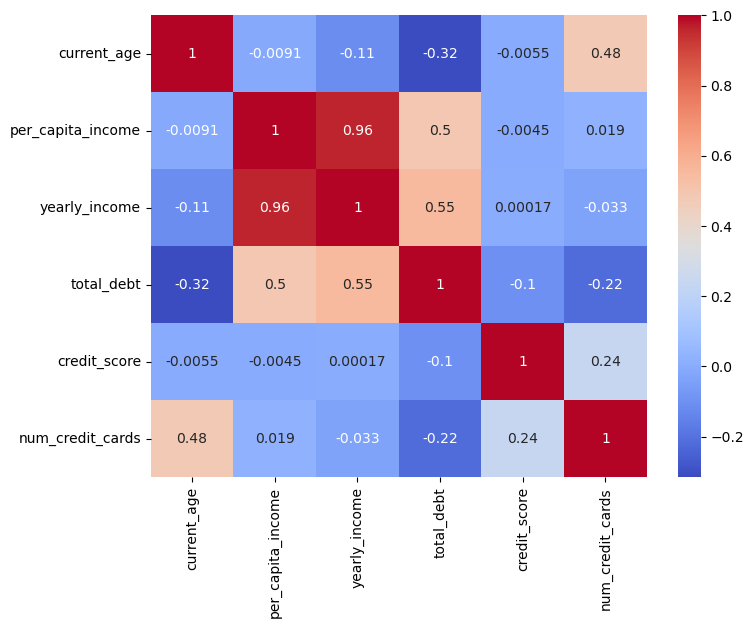

In [81]:
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

# On remarque que les variables 'yearly_income' et 'per_capita_income' présentent une très forte corrélation (proche de 1). Elles apportent donc une information redondante. Afin de limiter la redondance et d'améliorer l'interprétabilité du modèle, on supprime l'une des deux variables.

In [82]:
#Suppression de la variable per_capita_income
X = X.drop(columns=['per_capita_income'])

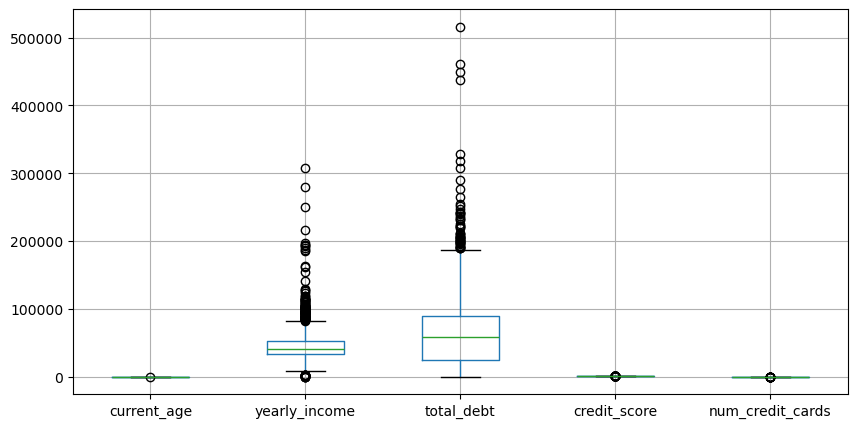

In [83]:
import matplotlib.pyplot as plt

X.boxplot(figsize=(10,5))
plt.show()

# Afficher les boîtes à moustaches des variables numériques afin de visualiser leur distribution et de détecter d'éventuelles valeurs aberrantes

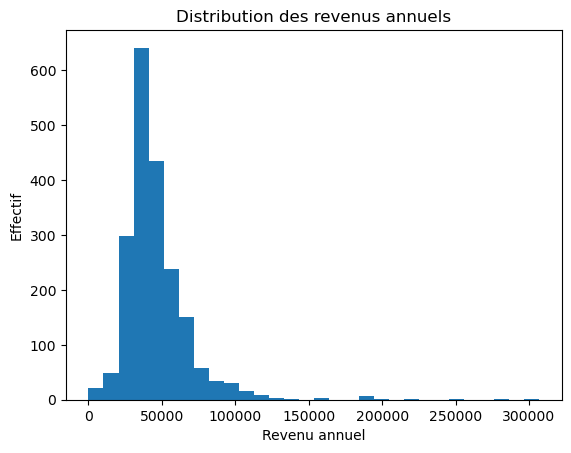

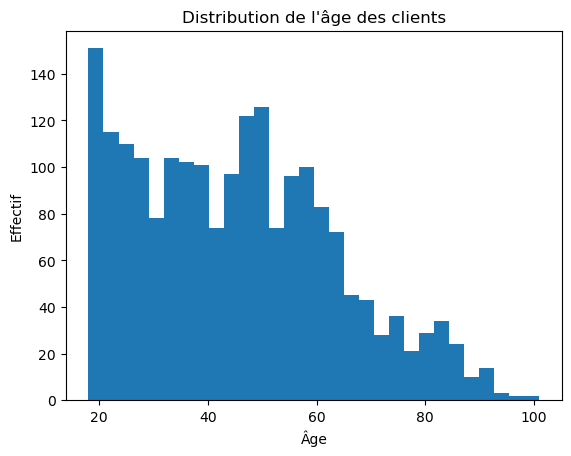

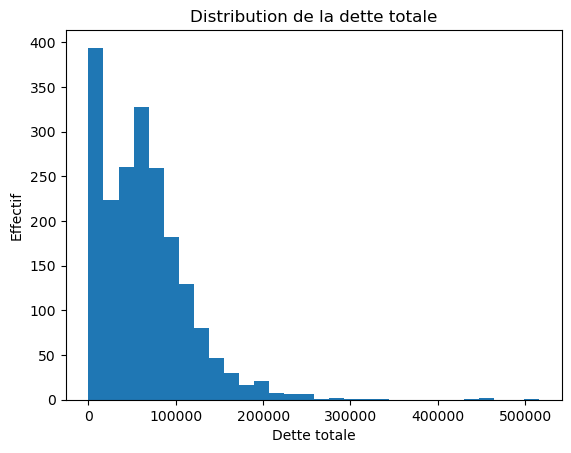

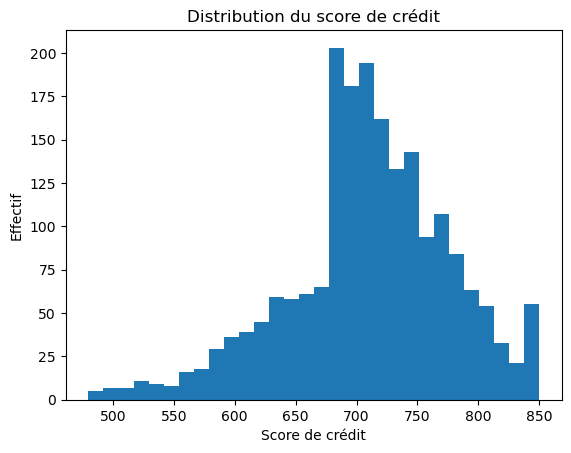

In [117]:
plt.hist(X["yearly_income"], bins=30)
plt.xlabel("Revenu annuel")
plt.ylabel("Effectif")
plt.title("Distribution des revenus annuels")
plt.show()
# Distribution de l'âge
plt.hist(X["current_age"], bins=30)
plt.xlabel("Âge")
plt.ylabel("Effectif")
plt.title("Distribution de l'âge des clients")
plt.show()
# Distribution de la dette totale
plt.hist(X["total_debt"], bins=30)
plt.xlabel("Dette totale")
plt.ylabel("Effectif")
plt.title("Distribution de la dette totale")
plt.show()
# Distribution du score de crédit
plt.hist(X["credit_score"], bins=30)
plt.xlabel("Score de crédit")
plt.ylabel("Effectif")
plt.title("Distribution du score de crédit")
plt.show()

### Les histogrammes montrent la distribution des variables utilisées pour le clustering. On observe que les revenus annuels et la dette totale présentent une dispersion importante avec quelques valeurs élevées, tandis que le score de crédit est relativement centré autour de sa moyenne.

In [119]:
users.loc[
    X["yearly_income"] < 1000,
    ["current_age",
     "yearly_income",
     "total_debt",
     "credit_score",
     "num_credit_cards"]
]

,current_age,yearly_income,total_debt,credit_score,num_credit_cards
662,41,$553,$740,719,3
751,53,$920,$1914,788,3
764,77,$1,$0,673,3
1342,47,$3,$5,750,2
1426,65,$645,$790,688,3
1543,63,$4,$0,691,3
1686,83,$2,$0,667,6
1731,64,$399,$323,729,3


### Les boxplots et l'analyse des observations extrêmes montrent la présence de quelques valeurs atypiques. Après vérification, ces valeurs correspondent à des profils clients plausibles et ne résultent pas d'erreurs de saisie. Elles ont donc été conservées afin de préserver la diversité des profils financiers et de ne pas supprimer des informations potentiellement importantes pour la segmentation.

In [118]:
# Normalisation des variables numériques afin qu'elles soient sur la même échelle
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Calcul de la moyenne et de l'écart-type sur les données, puis transformation des variables afin qu'elles soient centrées (moyenne = 0) et réduites (écart-type = 1)
X_scaled = scaler.fit_transform(X)
# Convertir les données normalisées en DataFrame afin de conserver les noms des colonnes
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

### Les variables ont été normalisées à l'aide de **StandardScaler** afin de les ramener sur une même échelle (moyenne égale à 0 et écart-type égal à 1). Cette étape est indispensable pour les méthodes de clustering, car elle évite que les variables ayant de grandes valeurs numériques (par exemple le revenu annuel ou la dette totale) dominent le calcul des distances. Ainsi, chaque variable contribue de manière équilibrée à la formation des clusters.

In [88]:
# Vérifier les statistiques descriptives après la normalisation
X_scaled.describe()

,current_age,yearly_income,total_debt,credit_score,num_credit_cards
count,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03
mean,-2.842171e-17,1.065814e-16,-5.684342e-17,-3.765876e-16,1.154632e-17
std,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00
min,-1.487901e+00,-1.988739e+00,-1.219525e+00,-3.418407e+00,-1.266364e+00
25%,-8.360635e-01,-5.610761e-01,-7.603731e-01,-4.275640e-01,-6.554793e-01
50%,-7.558603e-02,-2.162705e-01,-1.044898e-01,2.627031e-02,-4.459458e-02
75%,6.848914e-01,3.037655e-01,4.854543e-01,6.437826e-01,5.662901e-01
max,3.020644e+00,1.136745e+01,8.662735e+00,2.087125e+00,3.620714e+00


### On remarque que la moyenne (mean) est très proche de 0 et que l'écart-type (std) est proche de 1, ce qui confirme que les données ont été correctement standardisées.

# Benchmark des algorithmes de clustering
## Comparaison de K-Means et du clustering hiérarchique et DBSCAN afin de sélectionner le modèle offrant la meilleure qualité de segmentation.

In [89]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=3, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)

sil_kmeans = silhouette_score(X_scaled, labels_kmeans)
print("Silhouette K-Means :", sil_kmeans)

Silhouette K-Means : 0.2276262547603744


c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


In [90]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=3)
labels_agg = agg.fit_predict(X_scaled)

sil_agg = silhouette_score(X_scaled, labels_agg)
print("Silhouette Hiérarchique :", sil_agg)

Silhouette Hiérarchique : 0.2017980834673615


# L'algorithme DBSCAN nécessite principalement deux paramètres :

### eps : distance maximale entre deux observations pour qu'elles soient considérées comme voisines. Une valeur trop faible entraîne la création de nombreux points isolés, tandis qu'une valeur trop élevée peut fusionner plusieurs groupes en un seul.
### min_samples : nombre minimal d'observations présentes dans le voisinage (eps) pour qu'un point soit considéré comme un point central et qu'un cluster puisse être formé.

### Dans cette étude, les paramètres eps = 0.8 et min_samples = 5 ont été retenus après plusieurs essais sur les données standardisées. Le choix de min_samples = 5 correspond à une valeur couramment utilisée dans la littérature pour des jeux de données de taille moyenne, tandis que eps = 0.8 a permis d'évaluer la capacité de DBSCAN à détecter des groupes de densité dans les données.

In [91]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.8, min_samples=10)

labels_db = dbscan.fit_predict(X_scaled)
mask = labels_db != -1

sil_db = silhouette_score(
    X_scaled[mask],
    labels_db[mask]
)

print("Silhouette DBSCAN :", sil_db)

ValueError: Number of labels is 1. Valid values are 2 to n_samples - 1 (inclusive)

In [92]:
pd.Series(labels_db).value_counts().sort_index()

-1     391
 0    1609
Name: count, dtype: int64

## Avec ces paramètres, DBSCAN a identifié un seul cluster principal et 391 observations comme bruit (-1). Cette configuration ne permet pas d'obtenir une segmentation exploitable, ce qui explique pourquoi l'algorithme n'a pas été retenu.

In [103]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

ch_agg = calinski_harabasz_score(X_scaled, labels_agg)
db_agg = davies_bouldin_score(X_scaled, labels_agg)
ch_kmeans = calinski_harabasz_score(X_scaled, labels_kmeans)
db_kmeans = davies_bouldin_score(X_scaled, labels_kmeans)

In [105]:
import pandas as pd

benchmark = pd.DataFrame({
    "Algorithme": ["K-Means", "Clustering hiérarchique"],
    "Score de silhouette": [sil_kmeans, sil_agg],
    "Indice de Calinski-Harabasz": [ch_kmeans, ch_agg],
    "Indice de Davies-Bouldin": [db_kmeans, db_agg]
}).round(3)

benchmark

,Algorithme,Score de silhouette,Indice de Calinski-Harabasz,Indice de Davies-Bouldin
0,K-Means,0.228,549.728,1.467
1,Clustering hiérarchique,0.202,414.857,1.498


## Calcul des indices d'évaluation
## Les performances des algorithmes sont évaluées à l'aide de trois indices :
### - Score de silhouette : mesure la cohésion des clusters et leur séparation (plus élevé = meilleur).
### - Indice de Calinski-Harabasz : compare la dispersion entre les clusters à la dispersion au sein des clusters (plus élevé = meilleur).
### - Indice de Davies-Bouldin : mesure la similarité entre les clusters (plus faible = meilleur).

# Comparaison des algorithmes de clustering
### Les métriques calculées permettent d'évaluer et de comparer la qualité des partitions obtenues par K-Means et le clustering hiérarchique.
### Le modèle le plus performant sera sélectionné pour la segmentation des clients c'est donc K-means.

# On commence l'application du modèle K-means et on commence par le choix de K à l'aide de la méthode du coude

In [97]:
from sklearn.cluster import KMeans

inertias = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have

<Figure size 800x500 with 0 Axes>

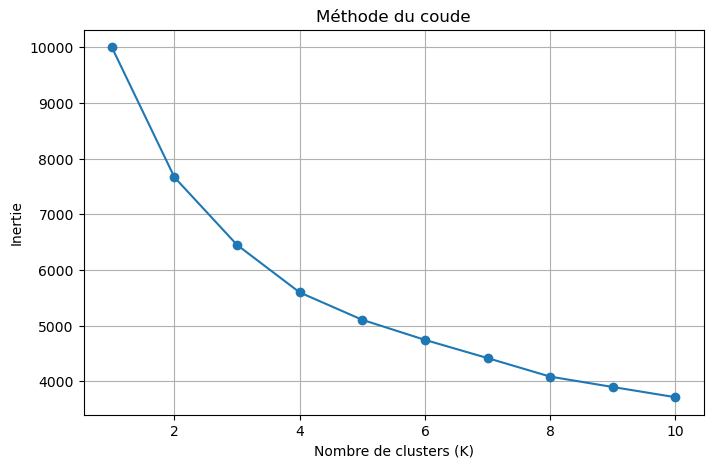

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(range(1,11), inertias, marker='o')
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode du coude")
plt.grid(True)
plt.show()

### La méthode du coude consiste à calculer l'inertie pour plusieurs valeurs de K et à tracer son évolution. Le nombre optimal de clusters correspond au point où la diminution de l'inertie devient moins importante, formant un « coude » sur la courbe.

### La méthode de coude ne présente pas une estimation exacte du nombre de cluster adapté(ce serait entre 3 et 5 ) donc on utilise la méthode de silhouette

In [95]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append(score)
    print(f"K = {k} | Score de silhouette = {score:.4f}")

c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


K = 2 | Score de silhouette = 0.2252
K = 3 | Score de silhouette = 0.2276


c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


K = 4 | Score de silhouette = 0.2118
K = 5 | Score de silhouette = 0.1861


c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


K = 6 | Score de silhouette = 0.1829
K = 7 | Score de silhouette = 0.1756


c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


K = 8 | Score de silhouette = 0.1800
K = 9 | Score de silhouette = 0.1799
K = 10 | Score de silhouette = 0.1728


### La méthode de silhouette évalue la qualité du partitionnement en mesurant la cohésion des observations au sein de leur cluster et leur séparation par rapport aux autres clusters. La valeur de K qui obtient le score de silhouette le plus élevé est généralement retenue comme le meilleur choix.

### Le choix du nombre optimal de clusters a été réalisé en combinant la méthode du coude et le coefficient de silhouette. La méthode du coude a permis d'identifier une zone de stabilisation de l'inertie à partir de K=3, tandis que le score de silhouette a atteint sa valeur maximale pour ce même nombre de clusters (0,2276). Les deux méthodes conduisant à la même conclusion, le choix de K=3 a été retenu pour l'entraînement du modèle K-Means. Ce compromis permet d'obtenir une segmentation cohérente et suffisamment discriminante pour l'analyse des profils clients.

In [111]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42) # random_state permet de fixer l'initialisation aléatoire des centroïdes

kmeans.fit(X_scaled)

c:\Users\rimla\Downloads\anac3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


KMeans(n_clusters=3, random_state=42)

In [112]:
# Associer chaque client au cluster correspondant
X["cluster"] = kmeans.predict(X_scaled)

In [113]:
#Nombre de clients dans chaque cluster
X["cluster"].value_counts()

cluster
0    1015
1     728
2     257
Name: count, dtype: int64

In [114]:
#Moyenne des 5 variables par clusters
X.groupby("cluster")[[
    "current_age",
    "yearly_income",
    "total_debt",
    "credit_score",
    "num_credit_cards"
]].mean()

,current_age,yearly_income,total_debt,credit_score,num_credit_cards
cluster,,,,,
0,34.802956,41298.788177,62341.717241,698.618719,2.175369
1,62.041209,39242.114011,34592.178571,727.973901,4.458791
2,40.046693,81498.968872,151593.147860,701.968872,2.692607


## Interprétation des clusters

### Cluster 0 : Clients à revenus moyens

- **Âge moyen :** 34,8 ans
- **Revenu annuel moyen :** 41 299
- **Dette moyenne :** 62 342
- **Score de crédit moyen :** 699
- **Nombre moyen de cartes de crédit :** 2,18

**Interprétation :**

Ce cluster regroupe principalement des clients relativement jeunes disposant de revenus et d'un niveau d'endettement modérés. Leur score de crédit est satisfaisant et ils possèdent peu de cartes de crédit. Ils représentent une clientèle standard pouvant être ciblée par des offres bancaires classiques ou des produits d'épargne.

### Cluster 1 : Clients expérimentés et solvables

- **Âge moyen :** 62,0 ans
- **Revenu annuel moyen :** 39 242
- **Dette moyenne :** 34 592
- **Score de crédit moyen :** 728
- **Nombre moyen de cartes de crédit :** 4,46

**Interprétation :**

Ce cluster est constitué de clients plus âgés présentant le meilleur score de crédit et le niveau d'endettement le plus faible. Ils possèdent davantage de cartes de crédit, ce qui traduit une relation bancaire plus ancienne et une bonne gestion financière. Ce profil est particulièrement adapté à des offres premium ou à des programmes de fidélisation.

### Cluster 2 : Clients à revenus élevés

- **Âge moyen :** 40,0 ans
- **Revenu annuel moyen :** 81 499
- **Dette moyenne :** 151 593
- **Score de crédit moyen :** 702
- **Nombre moyen de cartes de crédit :** 2,69

**Interprétation :**

Ce cluster regroupe des clients ayant les revenus les plus élevés, mais également le niveau d'endettement le plus important. Malgré cette dette élevée, leur score de crédit reste satisfaisant, ce qui peut traduire une bonne capacité de remboursement. Ce groupe constitue une cible pertinente pour des offres de financement, d'investissement ou de gestion de patrimoine.

## Intérêt métier

Cette segmentation met en évidence trois profils de clients aux comportements financiers distincts. Elle peut être exploitée par un établissement financier pour personnaliser les offres commerciales, adapter les stratégies marketing, améliorer la gestion des risques et renforcer la relation client.

## Les données utilisées pour le clustering comportent plusieurs variables (âge, revenu annuel, dette totale, score de crédit et nombre de cartes de crédit). Afin de faciliter leur visualisation, une Analyse en Composantes Principales (ACP) est appliquée. Cette méthode réduit la dimension des données en conservant la plus grande partie possible de leur variabilité.

In [106]:
from sklearn.decomposition import PCA

# Réduction de 6 dimensions à 2
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

In [107]:
print("Variance expliquée par chaque composante :")
print(pca.explained_variance_ratio_)

print("\nVariance expliquée totale :")
print(pca.explained_variance_ratio_.sum())

Variance expliquée par chaque composante :
[0.38108052 0.24869825]

Variance expliquée totale :
0.6297787654571636


### Les deux premières composantes principales expliquent environ 63 % de la variance totale des données. Cela signifie qu'elles conservent une part importante de l'information initiale, ce qui rend la projection en deux dimensions suffisamment représentative pour visualiser la structure des clusters.

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

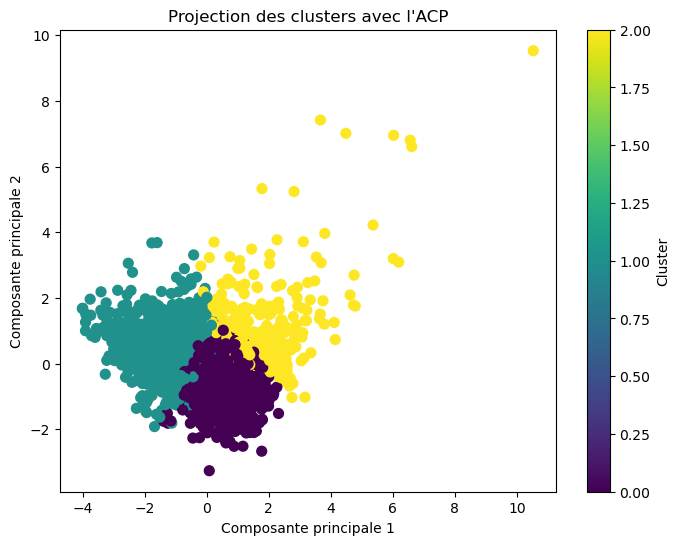

In [110]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=labels_kmeans,
    cmap="viridis",
    s=50
)

plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.title("Projection des clusters avec l'ACP")

plt.colorbar(label="Cluster")

plt.show()

### La projection des données par ACP montre une séparation globale des trois clusters obtenus par K-Means. Un léger chevauchement est observé entre certains groupes, ce qui reste cohérent avec le score de silhouette obtenu. Cette visualisation confirme la pertinence de la segmentation réalisée.

In [ ]:
import joblib

# Sauvegarde du modèle K-Means
joblib.dump(kmeans, "kmeans_model.pkl")

# Sauvegarde du StandardScaler
joblib.dump(scaler, "scaler.pkl")

### Le modèle entraîné ainsi que le StandardScaler sont sauvegardés afin de permettre la prédiction du cluster de nouveaux clients sans nécessiter un nouvel entraînement.

# Conclusion

Dans ce projet, une segmentation de clients financiers a été réalisée à l'aide de techniques de clustering non supervisé. Après le prétraitement des données (nettoyage, sélection des variables et standardisation), plusieurs méthodes de clustering ont été comparées.

La méthode du coude et le score de silhouette ont permis de retenir **K = 3** comme nombre optimal de clusters pour l'algorithme K-Means. Une comparaison avec le clustering hiérarchique et DBSCAN a montré que **K-Means** obtenait les meilleures performances sur ce jeu de données, avec une meilleure séparation des groupes selon les indices de silhouette, de Calinski-Harabasz et de Davies-Bouldin. La visualisation par Analyse en Composantes Principales (ACP) a confirmé la cohérence de la segmentation obtenue.

L'analyse des clusters a permis d'identifier trois profils de clients distincts : des clients à revenus moyens, des clients plus âgés et financièrement stables, ainsi que des clients à revenus élevés présentant un niveau d'endettement important. Cette segmentation peut être utilisée pour adapter les stratégies marketing, personnaliser les offres financières et améliorer la gestion de la relation client.

## Perspectives d'amélioration

Plusieurs pistes peuvent être envisagées pour améliorer ce travail :

- Tester d'autres algorithmes de clustering, tels que Gaussian Mixture Models (GMM), K-Medoids ou HDBSCAN.
- Intégrer davantage de variables décrivant le comportement financier des clients afin d'obtenir une segmentation plus fine.
- Développer une application permettant d'affecter automatiquement un nouveau client au cluster le plus approprié.
- Valider la stabilité des clusters sur d'autres jeux de données afin d'évaluer leur robustesse.